# Plug in custom image features

Any encoder can supply an `n_spots × n_features` array. This fully runnable example computes **simple RGB statistics from the real full-resolution H&E image** for all labelled DLPFC 151673 spots, then passes the array through `img.extract_image_features(method=features)`.

These lightweight descriptors demonstrate the interface. They are **not BYOL, a foundation model, or a paper reproduction**. Replace the descriptor calculation with your own encoder and align its barcode-indexed output to `adata.obs_names`. Install the `[image]` extra for patch cropping; precomputed arrays alone do not need it. Set `STAIG_DATA` to an unpacked `Dataset` directory, or use the on-demand download below.

In [1]:
import os
import warnings

# Compact warnings preserve their message without machine-specific source paths.
def show_warning(message, category, filename, lineno, file=None, line=None):
    print(f"{category.__name__}: {message}")
warnings.showwarning = show_warning

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import staig
from staig import datasets, img, metrics, pl, pp

torch.set_num_threads(min(4, os.cpu_count() or 1))
plt.rcParams.update({"figure.figsize": (4.5, 4), "figure.dpi": 85})
root = os.getenv("STAIG_DATA")  # Unpacked Dataset root; None uses ./Dataset.
device = "cpu"  # Deliberately avoids the shared GPU.
print({"staig": staig.__version__, "torch": torch.__version__, "device": device})

{'staig': '2.0.0', 'torch': '2.11.0+cu128', 'device': 'cpu'}


## Read raw data and crop real H&E patches

`image_features=None` avoids loading the published representation. Crops use full-resolution coordinates and the fiducial scale; resizing to 32 pixels keeps this demonstration small. No frequency filter is used for the RGB descriptors.

[staig] load_labels: dropped 28 unlabelled spots


[staig] extract_patches: 3611 patches of 506 px (3.5 x d) -> 32x32


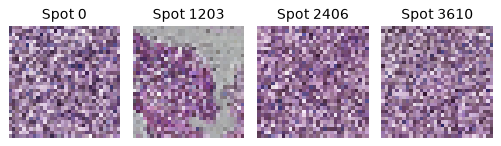

In [2]:
adata = datasets.load_dlpfc("151673", root=root, download=True, image_features=None)
patches = img.extract_patches(adata, patch_size=32)
assert patches.shape == (adata.n_obs, 32, 32, 3)
fig, axes = plt.subplots(1, 4, figsize=(6, 1.8))
for ax, index in zip(axes, np.linspace(0, adata.n_obs - 1, 4, dtype=int)):
    ax.imshow(patches[index])
    ax.set_title(f"Spot {index}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Build and attach a feature array

Per-channel means, standard deviations and quartiles produce 15 features per spot. Cropping preserves `adata.obs_names` order; an external model must preserve or explicitly reconstruct that alignment.

In [3]:
pixels = patches.reshape(adata.n_obs, -1, 3).astype(np.float32) / 255.0
quartiles = np.quantile(pixels, [0.25, 0.5, 0.75], axis=1).transpose(1, 0, 2)
features = np.concatenate([pixels.mean(axis=1), pixels.std(axis=1),
                           quartiles.reshape(adata.n_obs, -1)], axis=1).astype(np.float32)
assert features.shape == (adata.n_obs, 15)
assert np.isfinite(features).all()
img.extract_image_features(adata, method=features)
assert np.array_equal(adata.obsm["image_features"], features)
print({"feature_shape": features.shape,
       "method": adata.uns["staig"]["image"]["method"]})
del pixels, patches, quartiles

{'feature_shape': (3611, 15), 'method': 'precomputed'}


## Train with custom morphology

The graph model accepts feature widths other than 2048. We request 8 image PCs for these 15-dimensional descriptors. Use a fresh AnnData when swapping representations, or invalidate cached image PCs, pseudo-labels and edge probabilities.

In [4]:
model = staig.run(adata, n_clusters=7, preset="visium", n_image_pcs=8,
                  epochs=10, device=device, loss_chunk_size=256, seed=0, verbose=False)
assert adata.obsm["X_staig"].shape == (adata.n_obs, 64)
assert np.isfinite(adata.obsm["X_staig"]).all()
assert np.isfinite(model.history["loss"]).all()
assert len(model.history["loss"]) == model.config.epochs
assert adata.obs["staig_domain"].notna().all()
print({"spots": adata.n_obs, "genes": adata.n_vars,
       "input_features": adata.obsm["X_staig_input"].shape[1],
       "epochs": model.config.epochs,
       "edge_mode": adata.uns["staig"]["edge_removal"]["mode"],
       "negative_mask": adata.uns["staig"]["negatives"],
       "n_negatives": adata.uns["staig"]["n_negatives"]})

[staig] preprocess: 3611 spots x 3000 HVGs -> obsm['X_staig_input']


{'spots': 3611, 'genes': 33538, 'input_features': 3000, 'epochs': 10, 'edge_mode': 'image', 'negative_mask': 'pseudo_label', 'n_negatives': 'all'}


## Inspect the result

Better morphology representations require separate scientific validation.

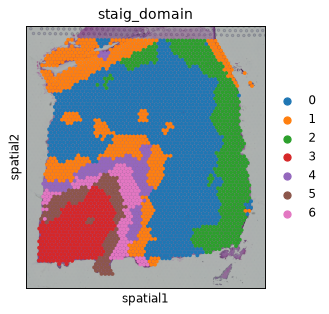

In [5]:
pl.spatial(adata, color="staig_domain", show=False)
plt.show()
